# Run analysis

Point `RUN_DIR` at one of the folders in `runs/` and run everything.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns

from utils.ipf import SEX, AGE, LANGUAGE, INCOME, TENURE, EDUCATION, PARTY
from utils.vec_results import load_first_preference_shares

# RUN_DIR = Path("runs/20261024-194731_2022-combined_sep2026")
RUN_DIR = Path("runs/20261103-112018_all-ones_sep2026")

gdf = gpd.read_file(RUN_DIR / "estimates.gpkg").to_crs(4326)
print((RUN_DIR / "config.json").read_text())
gdf.head()

{
  "survey": "sep2026",
  "seed_matrix": "all-ones",
  "seed_weight": 0.5,
  "upper_house_weight": 0.5,
  "apply_swing": false,
  "swing_floor": 0.01,
  "zero_method": "smoothing",
  "epsilon": 1e-06,
  "alpha": null,
  "population_base": "adult-citizen",
  "convergence_rate": 1e-10,
  "runs_dir": "runs"
}


,DISTRICT,REGION,population,Labor,Greens,Others,One Nation,L/NP,School Education,University Education,...,$45-125K,$125K+,Other Language at Home,English Only,Male,Female,Own Home Outright,Mortgage Holder,Renter,geometry
0,BASS,EASTERN VICTORIA,76985.478245,0.252586,0.131654,0.100530,0.218481,0.296748,0.384287,0.229906,...,0.404372,0.060547,0.228661,0.771339,0.484187,0.515813,0.305973,0.464212,0.229815,"MULTIPOLYGON (((145.33295 -38.4995, 145.33317 ..."
1,HASTINGS,EASTERN VICTORIA,43859.170405,0.230206,0.124571,0.099467,0.236157,0.309599,0.405165,0.170755,...,0.405464,0.073537,0.050692,0.949308,0.486597,0.513403,0.356189,0.452488,0.191323,"MULTIPOLYGON (((145.37211 -38.4176, 145.37113 ..."
2,KEW,SOUTHERN METROPOLITAN,47801.761132,0.237666,0.140058,0.121578,0.166173,0.334525,0.265273,0.553042,...,0.359846,0.204478,0.379755,0.620245,0.473786,0.526214,0.429625,0.308649,0.261726,"MULTIPOLYGON (((145.00203 -37.79646, 145.00214..."
3,CLARINDA,SOUTH-EASTERN METROPOLITAN,47616.570902,0.283992,0.135134,0.112854,0.179726,0.288293,0.419113,0.332920,...,0.366722,0.077298,0.533480,0.466520,0.494863,0.505137,0.347826,0.344790,0.307384,"MULTIPOLYGON (((145.16856 -37.96443, 145.16837..."
4,EILDON,NORTHERN VICTORIA,47662.660500,0.225009,0.113896,0.103203,0.231023,0.326869,0.380342,0.209274,...,0.371484,0.074474,0.054691,0.945309,0.496223,0.503777,0.428154,0.431561,0.140286,"MULTIPOLYGON (((145.22745 -37.30508, 145.22732..."


In [2]:
PARTY_COLOURS = {
    "Labor": "red",
    "L/NP": "blue",
    "Greens": "green",
    "One Nation": "orange",
    "Others": "grey",
}

## simplified geojson for plotly so the maps don't get huge
geo = gdf.set_index("DISTRICT")[["geometry"]].copy()
geo["geometry"] = geo.simplify(0.001)
geojson = geo.__geo_interface__

## statewide shares, population weighted
statewide = gdf[PARTY].mul(gdf["population"], axis=0).sum() / gdf["population"].sum()
statewide.round(3)

Labor         0.25
Greens        0.14
Others        0.11
One Nation    0.20
L/NP          0.30
dtype: float64

## 0. Modelled vs 2022 first preferences

How the IPF district estimates compare with the actual 2022 result.
`2022` is the VEC count, `modelled` is the IPF output for this run.

In [3]:
fpm = gdf.set_index("DISTRICT")[PARTY]
fp22 = load_first_preference_shares().reindex(fpm.index)[PARTY]
assert not fp22.isna().any().any(), "missing 2022 results for some districts"

pd.DataFrame({"2022 sd": fp22.std(), "modelled sd": fpm.std()}).round(3)

,2022 sd,modelled sd
Labor,0.111,0.026
Greens,0.076,0.022
Others,0.079,0.008
One Nation,0.012,0.023
L/NP,0.113,0.022


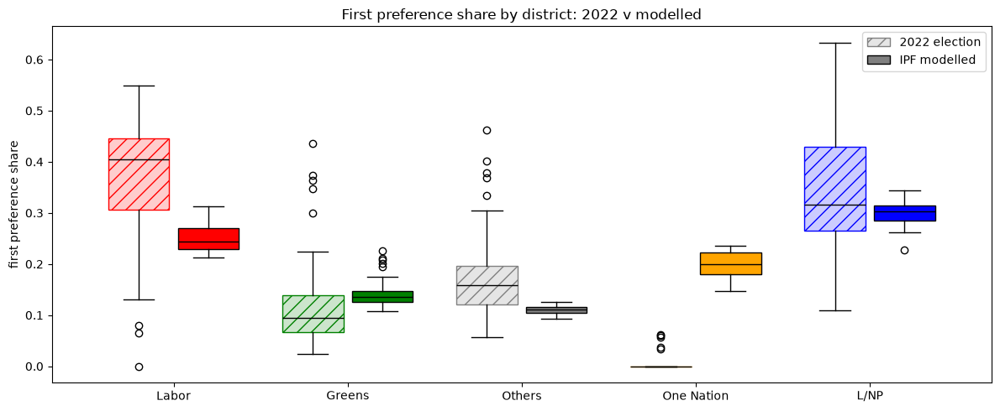

In [4]:
## spread of first preference share across districts, 2022 (left, hatched) v modelled (right, solid)
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(12, 5))
for i, p in enumerate(PARTY):
    colour = PARTY_COLOURS[p]
    old, new = ax.boxplot([fp22[p], fpm[p]], positions=[i - 0.2, i + 0.2], widths=0.35,
                          patch_artist=True, medianprops={"color": "black"})["boxes"]
    old.set(facecolor=to_rgba(colour, 0.2), edgecolor=colour, hatch="//")
    new.set(facecolor=colour, edgecolor="black")

ax.set_xticks(range(len(PARTY)), PARTY)
ax.set_ylabel("first preference share")
ax.legend(handles=[
    Patch(facecolor=to_rgba("grey", 0.2), edgecolor="grey", hatch="//", label="2022 election"),
    Patch(facecolor="grey", edgecolor="black", label="IPF modelled"),
])
ax.set_title("First preference share by district: 2022 v modelled")
plt.tight_layout()
plt.show()

Old v new per district. Dashed line is no change. One Nation only stood in a few
seats in 2022, so most of its 2022 values sit at 0.

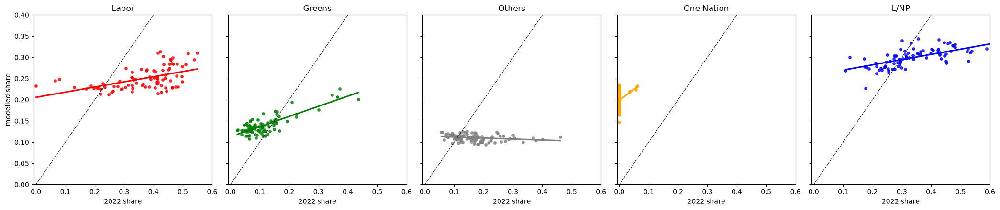

In [5]:
fig, ax = plt.subplots(1, len(PARTY), figsize=(21, 4.5), sharey=True, sharex = True)
for i, p in enumerate(PARTY):
    sns.regplot(x=fp22[p], y=fpm[p], color=PARTY_COLOURS[p], ci=None, scatter_kws={"s": 15}, ax=ax[i])
    lo = min(fp22[p].min(), fpm[p].min())
    hi = max(fp22[p].max(), fpm[p].max())
    ax[i].plot([0, 1], [0, 1], ls="--", color="black", lw=0.8)
    ax[i].set(title=p, xlabel="2022 share", ylabel="")
    ax[i].set_xlim(-0.0075, 0.6)
    ax[i].set_ylim(0, 0.4)
ax[0].set_ylabel("modelled share")
plt.tight_layout()
plt.show()

## 1. Party share vs demographic share

One row per demographic group, one panel per party. Each dot is a district.

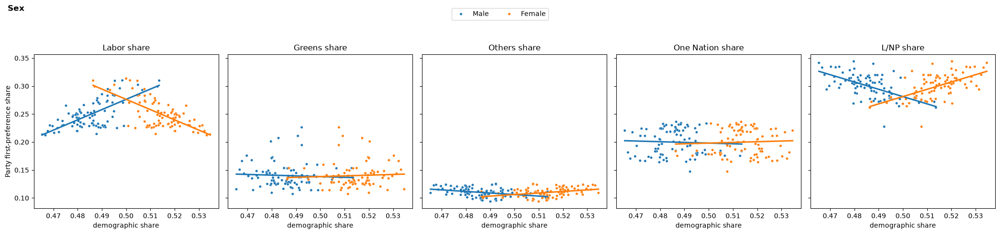

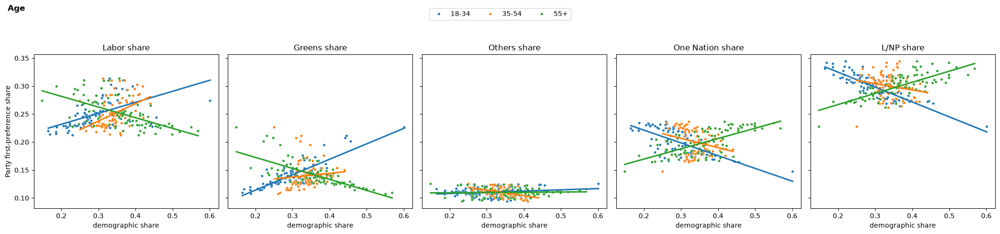

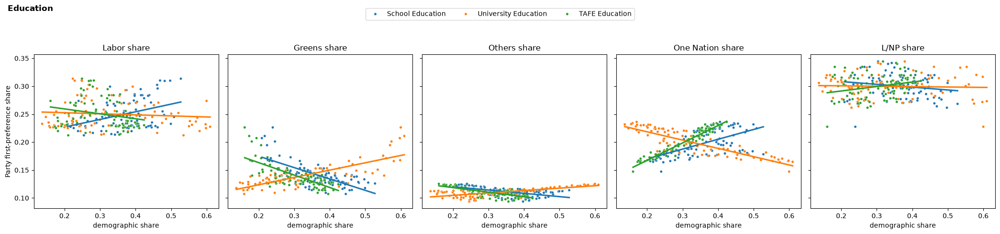

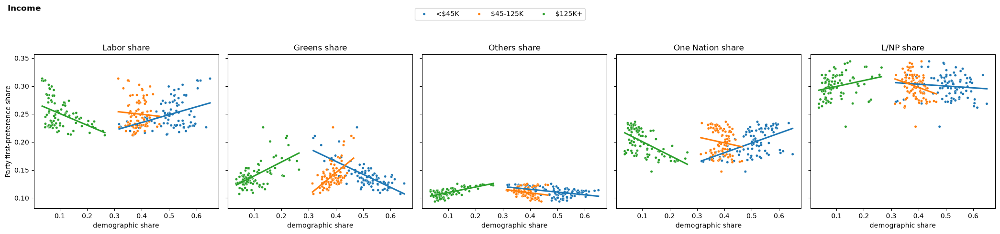

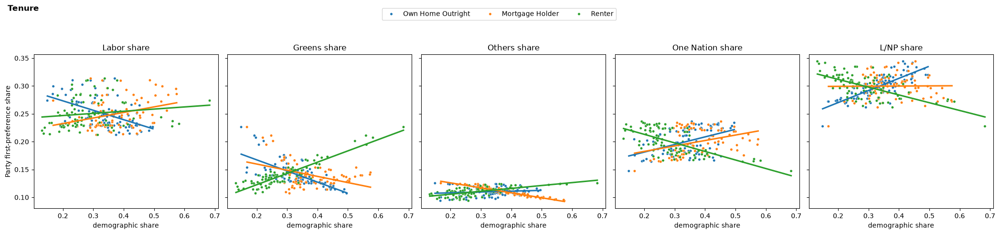

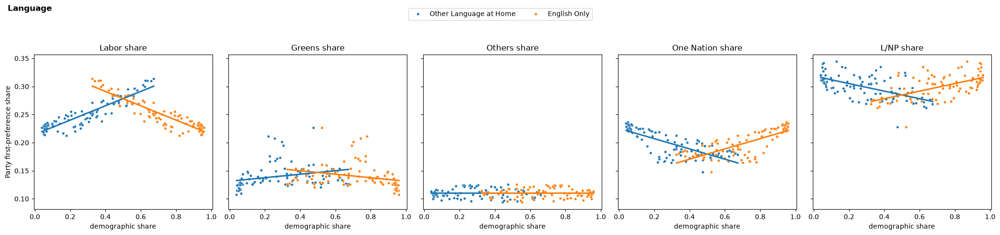

In [6]:
DEMOG_GROUPS = {
    "Sex": SEX,
    "Age": AGE,
    "Education": EDUCATION,
    "Income": INCOME,
    "Tenure": TENURE,
    "Language": LANGUAGE,
}

long = gdf.drop(columns=["geometry", "REGION"]).melt(id_vars=["DISTRICT", *PARTY])


def plot_demog_scatter(group_name, group_cols):
    data = long[long["variable"].isin(group_cols)]
    palette = dict(zip(group_cols, sns.color_palette(n_colors=len(group_cols))))

    fig, ax = plt.subplots(1, len(PARTY), figsize=(21, 4.5), sharey=True, sharex=True)
    for i, p in enumerate(PARTY):
        sns.scatterplot(data=data, x="value", y=p, hue="variable", palette=palette,
                        s=15, ax=ax[i], legend=(i == 0))
        for h in group_cols:
            sns.regplot(data=data[data["variable"] == h], x="value", y=p,
                        scatter=False, ci=None, color=palette[h], ax=ax[i])
        ax[i].set_title(f"{p} share")
        ax[i].set_xlabel("demographic share")
    ax[0].set_ylabel(f"Party first-preference share")
        
        

    handles, labels = ax[0].get_legend_handles_labels()
    ax[0].get_legend().remove()
    fig.legend(handles, labels, loc="upper center", ncol=len(group_cols), bbox_to_anchor=(0.5, 1.08))
    fig.suptitle(group_name, x=0.01, ha="left", y=1.08, fontweight="bold")
    plt.tight_layout()
    plt.show()


for name, cols in DEMOG_GROUPS.items():
    plot_demog_scatter(name, cols)

### Change in first preference v demographic share

Same groups, but the y axis is modelled minus 2022 first preference share for each
party, so positive = the party is modelled higher than it got in 2022. Shows which
demographics go with the swings.

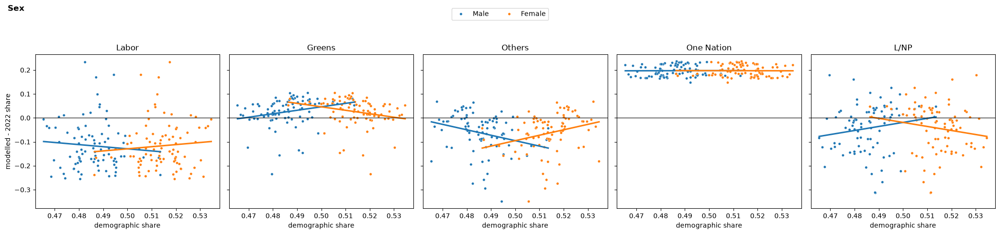

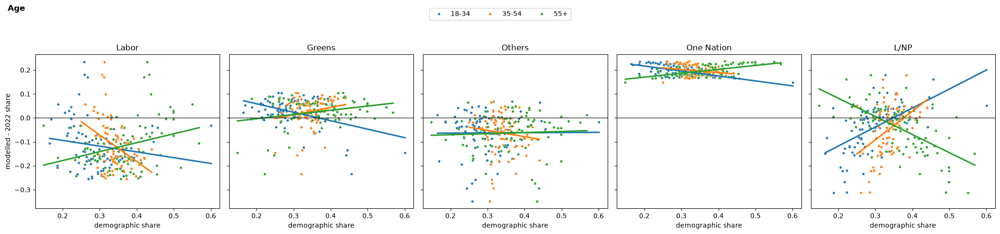

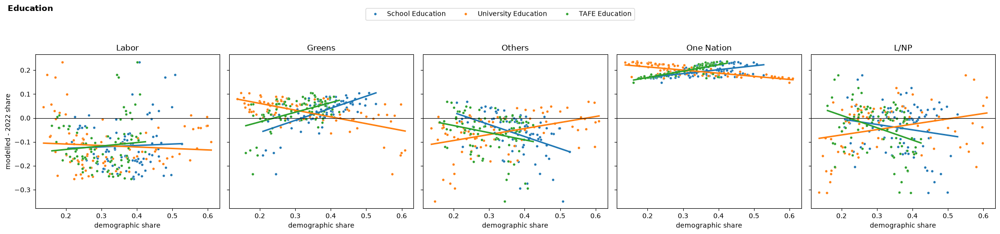

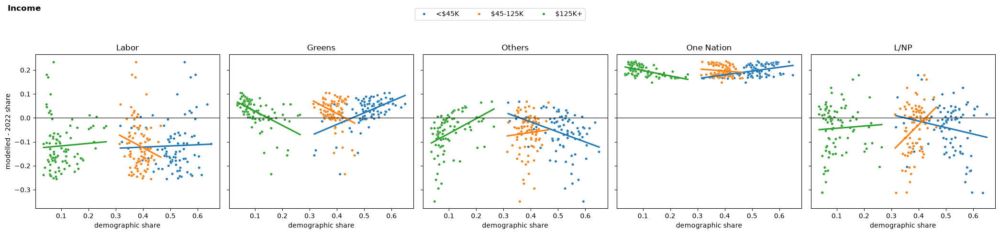

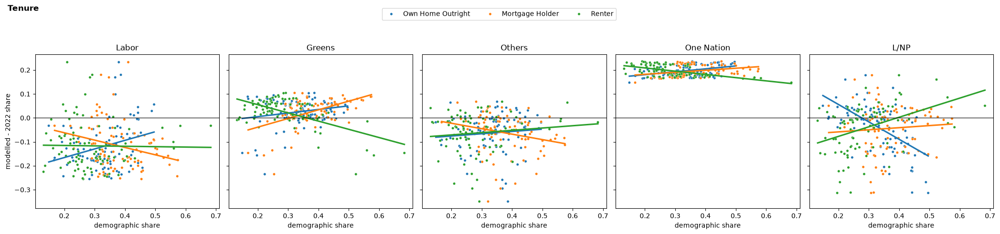

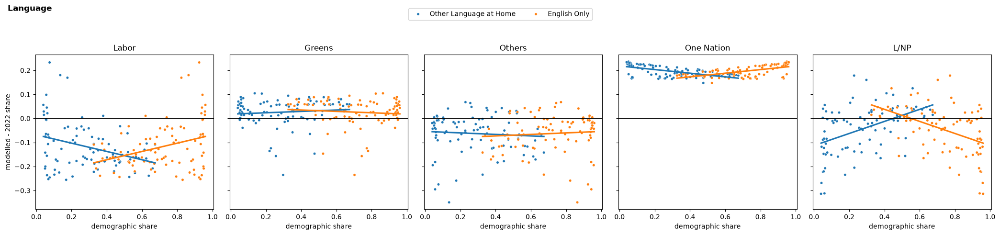

In [7]:
change = fpm - fp22
change_long = long[["DISTRICT", "variable", "value"]].merge(change.reset_index(), on="DISTRICT")


def plot_demog_change(group_name, group_cols):
    data = change_long[change_long["variable"].isin(group_cols)]
    data = data.assign(value=data["value"].astype(float))
    palette = dict(zip(group_cols, sns.color_palette(n_colors=len(group_cols))))

    fig, ax = plt.subplots(1, len(PARTY), figsize=(21, 4.5), sharey=True)
    for i, p in enumerate(PARTY):
        sns.scatterplot(data=data, x="value", y=p, hue="variable", palette=palette,
                        s=15, ax=ax[i], legend=(i == 0))
        for h in group_cols:
            sns.regplot(data=data[data["variable"] == h], x="value", y=p,
                        scatter=False, ci=None, color=palette[h], ax=ax[i])
        ax[i].axhline(0, color="black", lw=0.8)
        ax[i].set(title=p, xlabel="demographic share", ylabel="")
    ax[0].set_ylabel("modelled - 2022 share")

    handles, labels = ax[0].get_legend_handles_labels()
    ax[0].get_legend().remove()
    fig.legend(handles, labels, loc="upper center", ncol=len(group_cols), bbox_to_anchor=(0.5, 1.08))
    fig.suptitle(group_name, x=0.01, ha="left", y=1.08, fontweight="bold")
    plt.tight_layout()
    plt.show()


for name, cols in DEMOG_GROUPS.items():
    plot_demog_change(name, cols)

### Average swing by upper house region

District swing = modelled minus 2022 first preference share, averaged over the
districts in each upper house region. Dashed line is the survey's statewide swing
(survey topline minus the 2022 result).

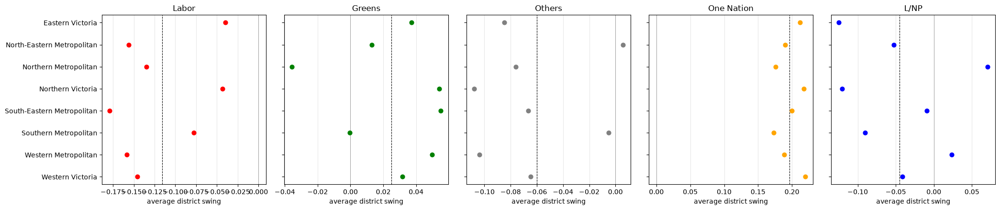

,Labor,Greens,Others,One Nation,L/NP
REGION,,,,,
Eastern Victoria,-4.0,3.7,-8.5,21.2,-12.5
North-Eastern Metropolitan,-15.6,1.3,0.6,19.0,-5.2
Northern Metropolitan,-13.4,-3.6,-7.6,17.6,7.1
Northern Victoria,-4.3,5.4,-10.8,21.7,-12.0
South-Eastern Metropolitan,-17.9,5.5,-6.6,20.0,-0.9
Southern Metropolitan,-7.8,-0.0,-0.5,17.3,-9.0
Western Metropolitan,-15.8,5.0,-10.4,18.9,2.4
Western Victoria,-14.6,3.2,-6.5,22.0,-4.1


In [8]:
import json

from utils.ipf import get_swing, load_survey

config = json.loads((RUN_DIR / "config.json").read_text())
survey_swing = get_swing(load_survey(config["survey"])[1])

region = gdf.set_index("DISTRICT")["REGION"].str.title()
region_swing = change.groupby(region.reindex(change.index)).mean().sort_index()

fig, ax = plt.subplots(1, len(PARTY), figsize=(21, 4.5), sharey=True)
for i, p in enumerate(PARTY):
    ax[i].scatter(region_swing[p], region_swing.index, color=PARTY_COLOURS[p], s=40, zorder=3)
    ax[i].axvline(survey_swing[p], color="black", ls="--", lw=0.8)
    ax[i].axvline(0, color="grey", lw=0.5)
    ax[i].grid(axis="x", alpha=0.3)
    ax[i].set(title=p, xlabel="average district swing")
ax[0].invert_yaxis()
plt.tight_layout()
plt.show()

region_swing.mul(100).round(1)

## 2. Interactive first preference map

Each district is coloured by the party with the highest first preference vote,
shaded darker the bigger that party's share. Hover for the full breakdown.

In [11]:
counts = fp["leader"].value_counts()

fig = go.Figure()
for p, colour in PARTY_COLOURS.items():
    d = fp[fp["leader"] == p]
    if d.empty:
        continue
    fig.add_trace(go.Choroplethmap(
        geojson=geojson,
        locations=d.index,
        z=d["leader_share"],
        zmin=zmin, zmax=zmax,
        colorscale=[[0, "white"], [1, colour]],
        showscale=False,
        showlegend=False,
        legendgroup=p,          # clicking the legend entry toggles this trace
        marker_opacity=0.8,
        marker_line_width=0.5,
        marker_line_color="white",
        name=p,
        text=d.index + "<br>" + hover[d.index],
        hovertemplate="<b>%{text}</b><extra></extra>",
    ))
    # dummy trace that only exists to draw the legend swatch
    fig.add_trace(go.Scattermap(
        lat=[None], lon=[None],
        mode="markers",
        marker=dict(size=12, color=colour),
        name=f"{p} ({counts[p]})",
        legendgroup=p,
        showlegend=True,
        hoverinfo="skip",
    ))

fig.update_layout(
    map_style="carto-positron",
    map_zoom=5.6,
    map_center={"lat": -37.0, "lon": 145.0},
    height=700,
    margin=dict(l=0, r=0, t=40, b=0),
    title="Leading party on first preferences",
    legend=dict(
        title="Leading party (districts ahead)",
        x=0.01, y=0.99,
        bgcolor="rgba(255,255,255,0.8)",
    ),
)


In [10]:
fp = gdf.drop(columns="geometry").set_index("DISTRICT")
fp["leader"] = fp[PARTY].idxmax(axis=1)
fp["leader_share"] = fp[PARTY].max(axis=1)

hover = fp[PARTY].apply(
    lambda r: "<br>".join(f"{p}: {r[p]:.1%}" for p in PARTY), axis=1
)

zmin, zmax = fp["leader_share"].min(), fp["leader_share"].max()

fig = go.Figure()
for p, colour in PARTY_COLOURS.items():
    d = fp[fp["leader"] == p]
    if d.empty:
        continue
    fig.add_trace(go.Choroplethmap(
        geojson=geojson,
        locations=d.index,
        z=d["leader_share"],
        zmin=zmin, zmax=zmax,
        colorscale=[[0, "white"], [1, colour]],
        showscale=False,
        marker_opacity=0.8,
        marker_line_width=0.5,
        marker_line_color="white",
        name=p,
        text=d.index + "<br>" + hover[d.index],
        hovertemplate="<b>%{text}</b><extra></extra>",
    ))

fig.update_layout(
    map_style="carto-positron",
    map_zoom=5.6,
    map_center={"lat": -37.0, "lon": 145.0},
    height=700,
    margin=dict(l=0, r=0, t=40, b=0),
    title="Leading party on first preferences",
)

fig.show()

fp["leader"].value_counts()

leader
L/NP     75
Labor    13
Name: count, dtype: int64

Same thing but one party at a time, each in its own colour — handy for seeing where
each party is strong even when it isn't leading. Use the buttons to switch party.

In [ ]:
fig = go.Figure()
for i, p in enumerate(PARTY):
    fig.add_trace(go.Choroplethmap(
        geojson=geojson,
        locations=fp.index,
        z=fp[p],
        zmin=0, zmax=fp[p].max(),
        colorscale=[[0, "white"], [1, PARTY_COLOURS[p]]],
        colorbar=dict(title=p, tickformat=".0%"),
        marker_opacity=0.8,
        marker_line_width=0.5,
        marker_line_color="white",
        name=p,
        visible=(i == 0),
        hovertemplate="<b>%{location}</b><br>" + p + ": %{z:.1%}<extra></extra>",
    ))

buttons = [
    dict(label=p, method="update",
         args=[{"visible": [q == p for q in PARTY]}, {"title.text": f"{p} first preference share"}])
    for p in PARTY
]
fig.update_layout(
    updatemenus=[dict(type="buttons", direction="right", buttons=buttons,
                      x=0, y=1.0, xanchor="left", yanchor="bottom")],
    map_style="carto-positron",
    map_zoom=5.6,
    map_center={"lat": -37.0, "lon": 145.0},
    height=700,
    margin=dict(l=0, r=0, t=90, b=0),
    title=f"{PARTY[0]} first preference share",
)
fig.show()

## 3. Who makes the top 2?

Rank the parties on first preferences in each district and take the top two.
`Others` is left out of the ranking — it's a bucket of lots of different
candidates, so it's never really one candidate sitting in 2nd place.

Anything that isn't a Labor v L/NP contest is flagged.

In [ ]:
CANDIDATES = ["Labor", "L/NP", "Greens", "One Nation"]

ranked = fp[CANDIDATES].apply(lambda r: r.sort_values(ascending=False).index.tolist(), axis=1)
fp["first"] = ranked.str[0]
fp["second"] = ranked.str[1]
fp["third"] = ranked.str[2]
fp["top2"] = ranked.apply(lambda r: " v ".join(sorted(r[:2])))
fp["classic"] = fp["top2"] == "L/NP v Labor"

fp["top2"].value_counts()

top2
L/NP v Labor         75
L/NP v One Nation    13
Name: count, dtype: int64

In [ ]:
non_classic = fp.loc[~fp["classic"], ["REGION", *CANDIDATES, "first", "second", "third"]]
non_classic.sort_values(["second", "REGION"])

,REGION,Labor,L/NP,Greens,One Nation,first,second,third
DISTRICT,,,,,,,,
HASTINGS,EASTERN VICTORIA,0.230206,0.309599,0.124571,0.236157,L/NP,One Nation,Labor
GIPPSLAND EAST,EASTERN VICTORIA,0.226323,0.319741,0.107162,0.233873,L/NP,One Nation,Labor
NEPEAN,EASTERN VICTORIA,0.219553,0.331088,0.109288,0.224275,L/NP,One Nation,Labor
MORNINGTON,EASTERN VICTORIA,0.213353,0.341563,0.115594,0.220445,L/NP,One Nation,Labor
GIPPSLAND SOUTH,EASTERN VICTORIA,0.229240,0.311955,0.118042,0.230846,L/NP,One Nation,Labor
EILDON,NORTHERN VICTORIA,0.225009,0.326869,0.113896,0.231023,L/NP,One Nation,Labor
OVENS VALLEY,NORTHERN VICTORIA,0.228546,0.314002,0.116288,0.229977,L/NP,One Nation,Labor
BENAMBRA,NORTHERN VICTORIA,0.228850,0.306183,0.127519,0.231153,L/NP,One Nation,Labor
EUROA,NORTHERN VICTORIA,0.228701,0.314987,0.113867,0.233090,L/NP,One Nation,Labor


How close is each minor party to getting into the top 2?
`gap_to_top2` = party's share minus the share of whoever is 2nd among the *other*
candidates. Positive means it's in the top 2, near zero means it's in the mix.

In [ ]:
def gap_to_top2(party):
    others = fp[[c for c in CANDIDATES if c != party]]
    second_best_other = others.apply(lambda r: r.nlargest(2).iloc[-1], axis=1)
    return fp[party] - second_best_other


fp["ONP gap"] = gap_to_top2("One Nation")
fp["GRN gap"] = gap_to_top2("Greens")

fp[["ONP gap", "GRN gap"]].describe()

,ONP gap,GRN gap
count,88.000000,88.000000
mean,-0.046281,-0.106722
std,0.035662,0.030183
min,-0.105753,-0.155752
25%,-0.078335,-0.124759
50%,-0.054982,-0.111550
75%,-0.013101,-0.098269
max,0.007550,-0.001258


In [ ]:
## categorical map: which minor party (if any) makes the top 2
def minor_in_top2(r):
    top2 = {r["first"], r["second"]}
    if {"One Nation", "Greens"} <= top2:
        return "One Nation + Greens"
    if "One Nation" in top2:
        return "One Nation"
    if "Greens" in top2:
        return "Greens"
    return "Labor v L/NP"


fp["minor_top2"] = fp.apply(minor_in_top2, axis=1)

TOP2_COLOURS = {
    "Labor v L/NP": "lightgrey",
    "One Nation": "orange",
    "Greens": "green",
    "One Nation + Greens": "purple",
}

fig = px.choropleth_map(
    fp.reset_index(),
    geojson=geojson,
    locations="DISTRICT",
    color="minor_top2",
    color_discrete_map=TOP2_COLOURS,
    category_orders={"minor_top2": list(TOP2_COLOURS)},
    hover_data={"first": True, "second": True, "ONP gap": ":.1%", "GRN gap": ":.1%", "minor_top2": False},
    map_style="carto-positron",
    zoom=5.6,
    center={"lat": -37.0, "lon": 145.0},
    opacity=0.75,
    height=700,
)
fig.update_layout(margin=dict(l=0, r=0, t=40, b=0), title="Where One Nation / Greens make the top 2", legend_title="")
fig.show()

## 4. Two party preferred (Labor v L/NP)

Using the survey's preference flows:
Greens 90-10 to Labor, One Nation 81-19 to L/NP, Others 58-42 to Labor.

Caveat: in the seats flagged above the real final count won't be Labor v L/NP,
so the 2PP there is a bit hypothetical.

In [ ]:
## share of each party's vote that flows to Labor (L/NP gets the rest)
PREF_TO_LABOR = {
    "Labor": 1.0,
    "L/NP": 0.0,
    "Greens": 0.90,
    "One Nation": 0.19,
    "Others": 0.58,
}

fp["Labor 2PP"] = sum(fp[p] * w for p, w in PREF_TO_LABOR.items())
fp["L/NP 2PP"] = 1 - fp["Labor 2PP"]
fp["2PP winner"] = fp["Labor 2PP"].gt(0.5).map({True: "Labor", False: "L/NP"})

statewide_2pp = (statewide * pd.Series(PREF_TO_LABOR)).sum()
print(f"Statewide Labor 2PP: {statewide_2pp:.1%}  (L/NP {1 - statewide_2pp:.1%})")
print(fp["2PP winner"].value_counts())

Statewide Labor 2PP: 47.8%  (L/NP 52.2%)
2PP winner
L/NP     64
Labor    24
Name: count, dtype: int64


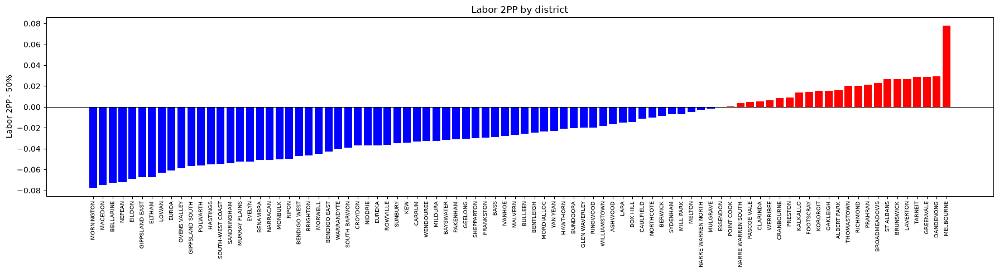

In [ ]:
## pendulum style - sorted by Labor 2PP
pend = fp.sort_values("Labor 2PP")
fig, ax = plt.subplots(figsize=(18, 5))
ax.bar(pend.index, pend["Labor 2PP"] - 0.5,
       color=pend["2PP winner"].map(PARTY_COLOURS))
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Labor 2PP - 50%")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.set_title("Labor 2PP by district")
plt.tight_layout()
plt.show()

In [ ]:
fig = px.choropleth_map(
    fp.reset_index(),
    geojson=geojson,
    locations="DISTRICT",
    color="Labor 2PP",
    color_continuous_scale="RdBu_r",
    color_continuous_midpoint=0.5,
    hover_data={"Labor 2PP": ":.1%", "L/NP 2PP": ":.1%", "top2": True},
    map_style="carto-positron",
    zoom=5.6,
    center={"lat": -37.0, "lon": 145.0},
    opacity=0.75,
    height=700,
)
fig.update_layout(margin=dict(l=0, r=0, t=40, b=0), title="Labor two party preferred")
fig.show()

Alternative 2PP map: only show a 2PP where the top 2 really is Labor v L/NP. Where
Greens or One Nation make the top 2, the seat is shaded in that party's colour by its
first preference share instead of pushing its vote onto Labor / L/NP.

In [ ]:
MINORS = ["Greens", "One Nation"]

classic = fp[fp["classic"]]
minor = fp[~fp["classic"]].copy()
## the minor party in the top 2 (the higher placed one if both are)
minor["minor_party"] = minor.apply(lambda r: r["first"] if r["first"] in MINORS else r["second"], axis=1)
minor_max = max(minor.loc[minor["minor_party"] == p, p].max() for p in minor["minor_party"].unique())

fig = go.Figure()
fig.add_trace(go.Choroplethmap(
    geojson=geojson,
    locations=classic.index,
    z=classic["Labor 2PP"],
    colorscale="RdBu_r",
    zmid=0.5,
    colorbar=dict(title="Labor 2PP", tickformat=".0%", len=0.45, y=0.75),
    marker_opacity=0.8,
    marker_line_width=0.5,
    marker_line_color="white",
    name="Labor v L/NP",
    text=classic.index + "<br>Labor 2PP: " + classic["Labor 2PP"].map("{:.1%}".format),
    hovertemplate="<b>%{text}</b><extra></extra>",
))
for j, p in enumerate(MINORS):
    d = minor[minor["minor_party"] == p]
    if d.empty:
        continue
    fig.add_trace(go.Choroplethmap(
        geojson=geojson,
        locations=d.index,
        z=d[p],
        zmin=0, zmax=minor_max,
        colorscale=[[0, "white"], [1, PARTY_COLOURS[p]]],
        colorbar=dict(title=f"{p} FP", tickformat=".0%", len=0.22, y=0.38 - 0.25 * j),
        marker_opacity=0.8,
        marker_line_width=0.5,
        marker_line_color="white",
        name=p,
        text=d.index + "<br>" + d["top2"] + "<br>" + hover[d.index],
        hovertemplate="<b>%{text}</b><extra></extra>",
    ))

fig.update_layout(
    map_style="carto-positron",
    map_zoom=5.6,
    map_center={"lat": -37.0, "lon": 145.0},
    height=700,
    margin=dict(l=0, r=0, t=40, b=0),
    title="Labor 2PP where it's Labor v L/NP, otherwise the minor party's first preference share",
)
fig.show()

minor["minor_party"].value_counts()

minor_party
One Nation    13
Name: count, dtype: int64

In [ ]:
## closest seats
fp.assign(margin=(fp["Labor 2PP"] - 0.5).abs()).sort_values("margin")[
    ["REGION", "Labor 2PP", "2PP winner", "top2"]
].head(15)

,REGION,Labor 2PP,2PP winner,top2
DISTRICT,,,,
ESSENDON,NORTHERN METROPOLITAN,0.500091,Labor,L/NP v Labor
POINT COOK,WESTERN METROPOLITAN,0.500653,Labor,L/NP v Labor
MULGRAVE,SOUTH-EASTERN METROPOLITAN,0.498471,L/NP,L/NP v Labor
NARRE WARREN NORTH,SOUTH-EASTERN METROPOLITAN,0.497163,L/NP,L/NP v Labor
NARRE WARREN SOUTH,SOUTH-EASTERN METROPOLITAN,0.503649,Labor,L/NP v Labor
PASCOE VALE,NORTHERN METROPOLITAN,0.504685,Labor,L/NP v Labor
MELTON,WESTERN VICTORIA,0.494964,L/NP,L/NP v Labor
CLARINDA,SOUTH-EASTERN METROPOLITAN,0.505216,Labor,L/NP v Labor
WERRIBEE,WESTERN METROPOLITAN,0.506461,Labor,L/NP v Labor
